In [1]:
%pip install -q roboflow ultralytics

In [2]:
from getpass import getpass
from roboflow import Roboflow

rf = Roboflow(api_key=getpass("API key de Roboflow: "))
project = rf.workspace("ari-basconsuelo").project("logo-brand-wbytq")
dataset = project.version(1).download("yolo26")
print(dataset.location)

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to Logo-Brand-1 in yolo26:: 100%|██████████| 19282/19282 [00:02<00:00, 6847.00it/s] 


/content/Logo-Brand-1


In [4]:
from collections import Counter
from pathlib import Path
import yaml

ruta = Path(dataset.location)
nombres = yaml.safe_load(open(ruta / "data.yaml"))["names"]

for split in ["train", "valid", "test"]:
    cajas = Counter()
    imagenes = 0
    for f in (ruta / split / "labels").glob("*.txt"):
        imagenes += 1
        for linea in f.read_text().splitlines():
            if linea.strip():
                cajas[int(linea.split()[0])] += 1
    print(f"\n{split}  ({imagenes} imágenes)")
    for i, n in cajas.most_common():
        print(f"  {nombres[i]:<20} {n}")


train  (7227 imágenes)
  Adidas               873
  Nike                 851
  NFL                  734
  Coca-Cola            729
  Starbucks            707
  Puma                 674
  Emirates             594
  Under Armour         566
  Mercedes-Benz        555
  Chanel               552
  The North Face       546
  Toyota               535
  Apple Inc-           497
  Hard Rock Cafe       491
  Pepsi                483

valid  (1451 imágenes)
  Nike                 120
  The North Face       119
  Coca-Cola            116
  Starbucks            112
  Mercedes-Benz        110
  Under Armour         103
  NFL                  97
  Puma                 95
  Adidas               93
  Apple Inc-           87
  Toyota               85
  Hard Rock Cafe       79
  Chanel               77
  Pepsi                74
  Emirates             61

test  (961 imágenes)
  The North Face       89
  Adidas               79
  Nike                 78
  Under Armour         72
  Starbucks            68

In [5]:
for split in ["train", "valid", "test"]:
    vacias = [f.name for f in (ruta / split / "labels").glob("*.txt") if not f.read_text().strip()]
    print(f"{split}: {len(vacias)} imágenes sin cajas")
    print("  ejemplos:", vacias[:3])

train: 165 imágenes sin cajas
  ejemplos: ['chicago_1737165436087991049_20180317_jpg.rf.4f6d362981e93aea4fefdd2fedbca04d.txt', 'la_1712656049168617269_20180211_jpg.rf.b9c02c32a7b6eb29cfd8aef1c98cc96a.txt', 'houston_1714250742405173376_20180214_jpg.rf.299b92d9b9a4df905398d7e61f1fa507.txt']
valid: 23 imágenes sin cajas
  ejemplos: ['la_1228464726843804173_20160414_jpg.rf.53dbdf760a6ee3095f8cb4026bf4e116.txt', 'cleveland_1482245800490560937_20170330_jpg.rf.66297c650f16c44243a5467a2bda9494.txt', 'chicago_1724430013909847815_20180228_jpg.rf.36ccf86b81959b155a208ff19c7277ad.txt']
test: 23 imágenes sin cajas
  ejemplos: ['houston_1471545872516061388_20170316_jpg.rf.91cb8a06893b2c373c4d650d534e75e0.txt', 'houston_1739470436837764401_20180320_jpg.rf.f2393300ef2431d8dcc47c7dea5b7e3f.txt', 'la_2017_1550549625012890934_20170703_jpg.rf.57b41cd729c62740103377325e72c5bd.txt']


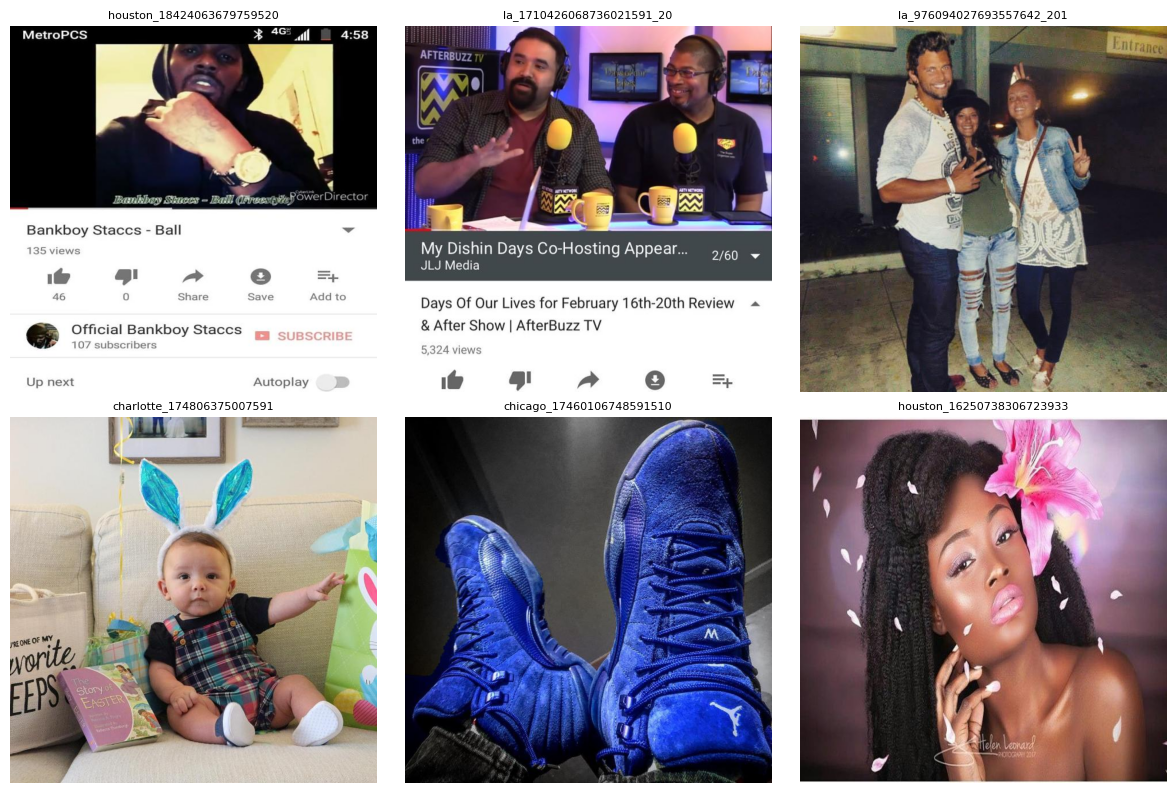

In [6]:
import random
import matplotlib.pyplot as plt
from PIL import Image

vacias = [f for f in (ruta / "train" / "labels").glob("*.txt") if not f.read_text().strip()]
muestra = random.sample(vacias, 6)

fig, ejes = plt.subplots(2, 3, figsize=(12, 8))
for eje, f in zip(ejes.flat, muestra):
    imagen = ruta / "train" / "images" / (f.stem + ".jpg")
    eje.imshow(Image.open(imagen))
    eje.set_title(f.stem[:25], fontsize=8)
    eje.axis("off")
plt.tight_layout()
plt.show()

In [7]:
from ultralytics import YOLO

model = YOLO("yolo26n.pt")
model.train(
    data=str(ruta / "data.yaml"),
    epochs=3,
    imgsz=640,
    batch=-1,
    seed=0,
    name="prueba_3ep",
)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.191 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=-1, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Logo-Brand-1/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=3, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0,

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7849ea24ce90>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,   

In [3]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [10]:
from pathlib import Path
from ultralytics import YOLO

carpeta_drive = Path("/content/drive/MyDrive/logo-detection/runs")
carpeta_drive.mkdir(parents=True, exist_ok=True)

model = YOLO("yolo26n.pt")
model.train(
    data=str(ruta / "data.yaml"),
    epochs=100,
    patience=20,
    imgsz=640,
    batch=-1,
    seed=0,
    project=str(carpeta_drive),
    name="base_yolo26n",
)

Ultralytics 8.4.191 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=-1, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Logo-Brand-1/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=base_yolo26n, nbs=64, nms=None, opset=None, optimize=Fals

: 

In [6]:
from ultralytics import YOLO
model = YOLO("/content/drive/MyDrive/logo-detection/runs/base_yolo26n/weights/last.pt")
model.train(resume=True)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.191 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=45, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Logo-Brand-1/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7b5060f6ed00>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,   

In [7]:
from pathlib import Path
from ultralytics import YOLO

carpeta_drive = Path("/content/drive/MyDrive/logo-detection/runs")
model = YOLO(str(carpeta_drive / "base_yolo26n/weights/best.pt"))
metricas = model.val(
    data="/content/Logo-Brand-1/data.yaml",
    split="val",
    conf=0.25,
    project=str(carpeta_drive),
    name="val_base_conf025",
)

Ultralytics 8.4.191 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,393,137 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1646.7±535.5 MB/s, size: 51.9 KB)
val: Scanning /content/Logo-Brand-1/valid/labels.cache... 1451 images, 23 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1451/1451 468.1Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 91/91 5.7it/s 15.9s0.1s
                   all       1451       1428      0.808      0.891      0.869      0.709
                Adidas         93         93      0.651      0.903      0.821       0.69
            Apple Inc-         87         87      0.933      0.958      0.946      0.768
                Chanel         77         77      0.813      0.766      0.755      0.605
             Coca-Cola        116        116      0.816      0.862        0.9      0.644
              Emirates        

In [8]:
from pathlib import Path
from ultralytics import YOLO

carpeta_drive = Path("/content/drive/MyDrive/logo-detection/runs")

model = YOLO("yolo26n.pt")
model.tune(
    data="/content/Logo-Brand-1/data.yaml",
    epochs=10,
    iterations=16,
    imgsz=640,
    batch=45,
    optimizer="AdamW",
    close_mosaic=2,
    seed=0,
    space={
        "lr0": (1e-5, 1e-2),
        "lrf": (0.01, 0.5),
        "weight_decay": (0.0, 0.001),
        "hsv_h": (0.0, 0.05),
        "hsv_v": (0.0, 0.9),
        "scale": (0.0, 0.9),
        "degrees": (0.0, 15.0),
        "fliplr": (0.0, 0.5),
        "mosaic": (0.0, 1.0),
    },
    plots=False,
    save=False,
    val=False,
    project=str(carpeta_drive),
    name="tune_yolo26n",
)

Tuner: Initialized Tuner instance with 'tune_dir=/content/drive/MyDrive/logo-detection/runs/tune_yolo26n'
Tuner: 💡 Learn about tuning at https://docs.ultralytics.com/guides/hyperparameter-tuning
Tuner: Starting iteration 1/16 with hyperparameters: {'lr0': 0.01, 'lrf': 0.01, 'weight_decay': 0.0005, 'hsv_h': 0.015, 'hsv_v': 0.4, 'scale': 0.5, 'degrees': 0.0, 'fliplr': 0.5, 'mosaic': 1.0}

MultiTrainer 1/1: fine-tuning on /content/Logo-Brand-1/data.yaml
MultiTrainer results saved to /content/drive/MyDrive/logo-detection/runs/multitrain/multitrain_results.json
Saved /content/drive/MyDrive/logo-detection/runs/tune_yolo26n/tune_scatter_plots.png
Saved /content/drive/MyDrive/logo-detection/runs/tune_yolo26n/tune_fitness.png

Tuner: 1/16 iterations complete ✅ (1186.58s)
Tuner: Results saved to /content/drive/MyDrive/logo-detection/runs/tune_yolo26n
Tuner: Best fitness=0.67076 observed at iteration 1
Tuner: Best fitness metrics are {'metrics/precision(B)': 0.77847, 'metrics/recall(B)': 0.8822, 

: 

### Resultado del tune
La búsqueda se interrumpió en la iteración 6 de 16 por un corte de la sesión de Colab.
Se completaron 5 iteraciones de 10 épocas. La mejor (iteración 1) alcanzó un mAP50-95 de 0,671 en validación.
Con tan pocos intentos, la búsqueda no permite sacar conclusiones sobre los hiperparámetros.
Los resultados están en Drive, en `runs/tune_yolo26n/tune_results.ndjson`.

In [4]:
from pathlib import Path
from ultralytics import YOLO

carpeta_drive = Path("/content/drive/MyDrive/logo-detection/runs")

model = YOLO("yolo26n.pt")
model.tune(
    data="/content/Logo-Brand-1/data.yaml",
    epochs=10,
    iterations=16,
    imgsz=640,
    batch=45,
    optimizer="AdamW",
    close_mosaic=2,
    seed=0,
    space={
        "lr0": (1e-5, 1e-2),
        "lrf": (0.01, 0.5),
        "weight_decay": (0.0, 0.001),
        "hsv_h": (0.0, 0.05),
        "hsv_v": (0.0, 0.9),
        "scale": (0.0, 0.9),
        "degrees": (0.0, 15.0),
        "fliplr": (0.0, 0.5),
        "mosaic": (0.0, 1.0),
    },
    plots=False,
    save=False,
    val=False,
    project=str(carpeta_drive),
    name="tune_yolo26n",
    resume=True,
)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Tuner: Initialized Tuner instance with 'tune_dir=/content/drive/MyDrive/logo-detection/runs/tune_yolo26n'
Tuner: 💡 Learn about tuning at https://docs.ultralytics.com/guides/hyperparameter-tuning
Tuner: Resuming tuning run /content/drive/MyDrive/logo-detection/runs/tune_yolo26n from iteration 6...
Tuner: Starting iteration 6/16 with hyperparameters: {'lr0': 0.00867, 'lrf': 0.01, 'weight_decay': 0.0005, 'hsv_h': 0.02695, 'hsv_v': 0.4, 'scale': 0.88875, 'degrees': 0.0, 'fliplr': 0.30352, 'mosaic': 1.0}

MultiTrainer 1/1: fine-tuning on /content/Logo-Brand-1/data.yaml
MultiTrainer results saved to /content/drive/MyDrive/logo-detection/runs/multitrain-2/multitrain_results.json
Saved /content/drive/MyDri

: 

In [4]:
from ultralytics import YOLO

model = YOLO("/content/drive/MyDrive/logo-detection/runs/base_yolo26n/weights/best.pt")
metricas_test = model.val(
    data="/content/Logo-Brand-1/data.yaml",
    split="test",
    project="/content/drive/MyDrive/logo-detection/runs",
    name="test_base_yolo26n",
)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.192 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,393,137 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1105.4±263.3 MB/s, size: 75.6 KB)
val: Scanning /content/Logo-Brand-1/test/labels... 961 images, 23 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 961/961 1.9Kit/s 0.5s0.1s
val: New cache created: /content/Logo-Brand-1/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 61/61 5.7it/s 10.7s0.1s
                   all        961        938      0.798      0.906      0.891       0.73
                Adidas         79    